# Group Model Comparison & Error-Aware Selection

Development-only comparison of the six individually owned headline models. The formal holdout remains quarantined. Average Precision is the primary ranking metric; fold variation, calibration and protocol completeness are considered before any winner is frozen.

Canonical FT input: completed GPU run `FT02_20261003T025004Z`, selected in `configs/analysis_registry.yaml`. It uses fixed FT02, inner-AP epoch selection and fresh fitting on inner-training rows; it is not an eight-candidate search. Historical FT evidence remains separate.

FT evaluation is complete for its declared fixed-candidate scope. Its `tuning_complete=False` flag records the absence of multi-candidate nested tuning, rather than an unfinished GPU evaluation.


## Load and validate aligned OOF evidence

Every registered model input is validated against frozen development IDs and folds, original development targets, and finite probabilities in [0, 1] before any analysis. EBM also retains its config-bound artifact checksum verification. Invalid or missing evidence stops the notebook.

### Canonical formal EBM input
The EBM input comes from `results/models/ebm/individual_IT25100429/`. Its loader verifies the configuration, formal artifact checksums, and frozen development-fold membership; missing or stale evidence stops loading. Parent-directory EBM results are historical default-only evidence. Three raw candidates participate in nested inner-AP selection; standardized variants are sensitivity experiments.


In [1]:
from pathlib import Path
import json, yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score, roc_auc_score, brier_score_loss, precision_recall_curve, f1_score

ROOT = Path.cwd().resolve()
if not (ROOT / "configs" / "analysis_registry.yaml").exists():
    for parent in ROOT.parents:
        if (parent / "configs" / "analysis_registry.yaml").exists():
            ROOT = parent
            break
import sys
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.evaluation.inputs import load_group_inputs
pd.set_option("display.max_columns", None)
registry, frames = load_group_inputs(ROOT)
print(f"Loaded {len(frames)} headline-model OOF files from development data only.")
from src.evaluation.calibration import expected_calibration_error
rows=[]; fold_rows=[]
reference_ids=None; reference_y=None
for model,d in frames.items():
    ids=d.Employee_ID.astype(int).to_numpy(); y=d.y_true.astype(int).to_numpy(); p=d.y_probability.astype(float).to_numpy()
    if reference_ids is None:
        reference_ids,reference_y=ids,y
    else:
        assert np.array_equal(reference_ids,ids)
        assert np.array_equal(reference_y,y)
    pr,rc,thr=precision_recall_curve(y,p)
    f1=np.divide(2*pr[:-1]*rc[:-1],pr[:-1]+rc[:-1],out=np.zeros_like(thr),where=(pr[:-1]+rc[:-1])>0)
    ix=int(np.nanargmax(f1)); t=float(thr[ix])
    rows.append({"model":model,"protocol":registry["models"][model]["protocol"],"tuning_complete":registry["models"][model]["tuning_complete"],"pooled_average_precision":average_precision_score(y,p),"pooled_roc_auc":roc_auc_score(y,p),"brier_score":brier_score_loss(y,p),"ece_10_bins":expected_calibration_error(y,p,10),"f1_at_0_5":f1_score(y,p>=0.5,zero_division=0),"f1_max_oof":f1_score(y,p>=t,zero_division=0),"f1_max_threshold":t})
    for fold,g in d.groupby("cv_fold"):
        fold_rows.append({"model":model,"cv_fold":int(fold),"average_precision":average_precision_score(g.y_true,g.y_probability),"roc_auc":roc_auc_score(g.y_true,g.y_probability),"brier_score":brier_score_loss(g.y_true,g.y_probability)})
comparison=pd.DataFrame(rows)
folds=pd.DataFrame(fold_rows)
stability=folds.groupby("model").agg(cv_ap_mean=("average_precision","mean"),cv_ap_sd=("average_precision","std"),cv_roc_mean=("roc_auc","mean"),cv_roc_sd=("roc_auc","std")).reset_index()
comparison=comparison.merge(stability,on="model").sort_values("pooled_average_precision",ascending=False)
prevalence=float(reference_y.mean())
comparison["ap_uplift_over_prevalence"]=comparison.pooled_average_precision-prevalence
out=ROOT/"results/comparison"; out.mkdir(parents=True,exist_ok=True)
comparison.to_csv(out/"model_comparison.csv",index=False); folds.to_csv(out/"fold_metrics_long.csv",index=False)
display(comparison.round(6))
print(f"No-skill prevalence: {prevalence:.6f}")

Rows before/after development isolation: 100,000 -> 80,000; Resigned prevalence=0.10010 (imbalanced; no resampling during saved review).


Loaded 6 headline-model OOF files from development data only.


,model,protocol,tuning_complete,pooled_average_precision,pooled_roc_auc,brier_score,ece_10_bins,f1_at_0_5,f1_max_oof,f1_max_threshold,cv_ap_mean,cv_ap_sd,cv_roc_mean,cv_roc_sd,ap_uplift_over_prevalence
2,XGBoost,Member 3 primary P1 one-hot; strict nested 8-c...,True,0.101181,0.502471,0.175329,0.227166,0.134522,0.182479,0.084618,0.101643,0.000990,0.504296,0.004184,0.001081
3,LightGBM,strict nested candidate selection,True,0.100153,0.498740,0.180215,0.234650,0.144030,0.182125,0.076155,0.100202,0.002446,0.498125,0.007699,0.000053
5,TabNet,strict nested candidate selection,True,0.099965,0.499317,0.186177,0.240548,0.147103,0.182062,0.079762,0.101700,0.003876,0.501142,0.008605,-0.000135
0,FT-Transformer,fixed FT02 GPU 5-fold OOF; inner-AP epoch sele...,False,0.099842,0.498905,0.247200,0.395671,0.164071,0.181990,0.383656,0.100396,0.001809,0.500347,0.003939,-0.000258
1,CatBoost,strict nested candidate selection,True,0.099346,0.500155,0.210753,0.313725,0.142168,0.181988,0.103214,0.100690,0.002784,0.501079,0.008469,-0.000754
4,EBM,nested inner-AP selection among three raw cand...,True,0.099000,0.495976,0.090109,0.003337,0.000000,0.181990,0.071095,0.099558,0.002073,0.496568,0.005315,-0.001100


No-skill prevalence: 0.100100


## Comparison figure and selection decision

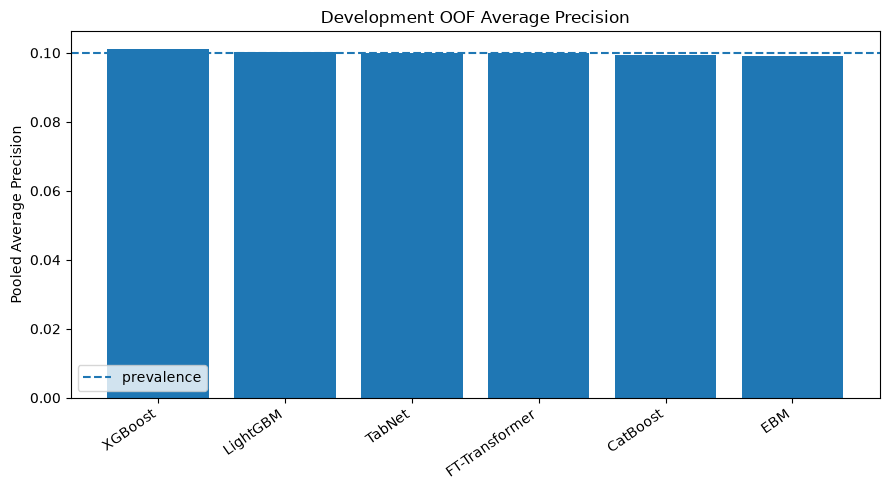

{'development_rows': 80000,
 'positive_prevalence': 0.1001,
 'ranking_leader': 'XGBoost',
 'leader_pooled_average_precision': 0.10118149850917421,
 'leader_ap_uplift_over_prevalence': 0.0010814985091742169,
 'final_model_frozen': False,
 'reason_not_frozen': 'All models remain near the no-skill baseline; candidate-selection and final-fit protocols differ across models.',
 'formal_holdout_accessed': False}

In [2]:
out=ROOT/"results/comparison"
plt.figure(figsize=(9,5)); plt.bar(comparison.model,comparison.pooled_average_precision); plt.axhline(prevalence,linestyle="--",label="prevalence"); plt.xticks(rotation=35,ha="right"); plt.ylabel("Pooled Average Precision"); plt.title("Development OOF Average Precision"); plt.legend(); plt.tight_layout(); plt.savefig(out/"figure_01_average_precision_comparison.png",dpi=160); plt.show()
leader=comparison.iloc[0]
summary={"development_rows":int(len(reference_ids)),"positive_prevalence":prevalence,"ranking_leader":str(leader.model),"leader_pooled_average_precision":float(leader.pooled_average_precision),"leader_ap_uplift_over_prevalence":float(leader.ap_uplift_over_prevalence),"final_model_frozen":False,"reason_not_frozen":"All models remain near the no-skill baseline; candidate-selection and final-fit protocols differ across models.","formal_holdout_accessed":False}
(out/"comparison_summary.json").write_text(json.dumps(summary,indent=2))
summary

## Conclusion

The numerical development leader is reported, but the absolute uplift over the approximately 10% prevalence baseline is very small. The repository therefore **does not claim operational predictive usefulness and does not freeze a final model**. This prevents the untouched holdout from being used to chase a better-looking result.